<a href="https://colab.research.google.com/github/handdung/bigdata/blob/main/week07_5756498_%EC%9D%B4%ED%99%98%EC%A4%80_ipynb%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7주차 과제
빅데이터프로그래밍 · 통계학과

**이름:이환준**
**학번:5756498**

## 과제 내용
은닉층 수와 활성화 함수를 변경하고 학습 결과를 비교합니다.

## 제출 방법
모든 셀을 실행해 출력과 그래프가 보이는 상태로 저장한 뒤 `week07_학번_이름.ipynb` 로 제출합니다.

**런타임 > 런타임 유형 변경 > T4 GPU** 를 먼저 선택하세요.


In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import pandas as pd

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

transform = transforms.ToTensor()
train_set = datasets.MNIST("./data", train=True,  download=True, transform=transform)
test_set  = datasets.MNIST("./data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=256, shuffle=False)


device: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 14.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 403kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.74MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.1MB/s]


## 공통 함수
아래 두 함수를 그대로 써서 모델만 바꿔 비교하세요.


In [2]:
def train_model(model, epochs=5, lr=1e-3):
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
        hist.append(evaluate(model))
        print(f"  epoch {epoch+1}  test acc {hist[-1][1]:.4f}")
    return model, hist


def evaluate(model):
    model.eval()
    loss_fn = nn.CrossEntropyLoss()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += loss_fn(out, y).item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()
    return loss_sum / total, correct / total


## 문제 1. 은닉층 수 비교 (35점)
은닉층이 **1개 · 2개 · 3개**인 MLP를 각각 작성해 5 epoch 학습하고, 시험 정확도를 비교하세요.
은닉층 크기는 128로 통일합니다.


In [3]:
# 답안
def make_mlp(n_hidden, act=nn.ReLU, hidden=128):
    layers = [nn.Flatten()]
    in_dim = 28 * 28
    for _ in range(n_hidden):
        layers += [nn.Linear(in_dim, hidden), act()]
        in_dim = hidden
    layers.append(nn.Linear(in_dim, 10))
    return nn.Sequential(*layers)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

results = {}   # 모델 이름 -> 결과
models = {}    # 모델 이름 -> 학습된 모델

for n in [1, 2, 3]:
    name = f"MLP-{n}-ReLU"
    print(name)
    torch.manual_seed(0)              # 공정한 비교를 위해 초기값 고정
    model, hist = train_model(make_mlp(n, nn.ReLU))
    models[name] = model
    results[name] = {"은닉층 수": n, "활성화": "ReLU",
                     "파라미터 수": count_params(model),
                     "시험 정확도": hist[-1][1], "hist": hist}

MLP-1-ReLU
  epoch 1  test acc 0.9349
  epoch 2  test acc 0.9515
  epoch 3  test acc 0.9626
  epoch 4  test acc 0.9685
  epoch 5  test acc 0.9732
MLP-2-ReLU
  epoch 1  test acc 0.9402
  epoch 2  test acc 0.9588
  epoch 3  test acc 0.9662
  epoch 4  test acc 0.9719
  epoch 5  test acc 0.9736
MLP-3-ReLU
  epoch 1  test acc 0.9456
  epoch 2  test acc 0.9590
  epoch 3  test acc 0.9668
  epoch 4  test acc 0.9711
  epoch 5  test acc 0.9743


## 문제 2. 활성화 함수 비교 (35점)
은닉층 2개 모델에서 활성화 함수를 **ReLU · Sigmoid · Tanh** 로 바꿔 각각 학습하고 결과를 비교하세요.


In [4]:
# 답안
for act_name, act in [("Sigmoid", nn.Sigmoid), ("Tanh", nn.Tanh)]:
    name = f"MLP-2-{act_name}"
    print(name)
    torch.manual_seed(0)
    model, hist = train_model(make_mlp(2, act))
    models[name] = model
    results[name] = {"은닉층 수": 2, "활성화": act_name,
                     "파라미터 수": count_params(model),
                     "시험 정확도": hist[-1][1], "hist": hist}

for name in ["MLP-2-ReLU", "MLP-2-Sigmoid", "MLP-2-Tanh"]:
    print(f"{name:15s} 최종 정확도 {results[name]['시험 정확도']:.4f}")

MLP-2-Sigmoid
  epoch 1  test acc 0.9160
  epoch 2  test acc 0.9385
  epoch 3  test acc 0.9491
  epoch 4  test acc 0.9582
  epoch 5  test acc 0.9627
MLP-2-Tanh
  epoch 1  test acc 0.9416
  epoch 2  test acc 0.9616
  epoch 3  test acc 0.9682
  epoch 4  test acc 0.9724
  epoch 5  test acc 0.9732
MLP-2-ReLU      최종 정확도 0.9736
MLP-2-Sigmoid   최종 정확도 0.9627
MLP-2-Tanh      최종 정확도 0.9732


## 문제 3. 결과 비교표와 그래프 (20점)
문제 1·2의 결과를 하나의 표로 정리하고, 학습 곡선을 한 그래프에 겹쳐 그리세요.

| 모델 | 은닉층 수 | 활성화 | 파라미터 수 | 시험 정확도 |


,모델,은닉층 수,활성화,파라미터 수,시험 정확도
0,MLP-1-ReLU,1,ReLU,101770,0.9732
1,MLP-2-ReLU,2,ReLU,118282,0.9736
2,MLP-3-ReLU,3,ReLU,134794,0.9743
3,MLP-2-Sigmoid,2,Sigmoid,118282,0.9627
4,MLP-2-Tanh,2,Tanh,118282,0.9732


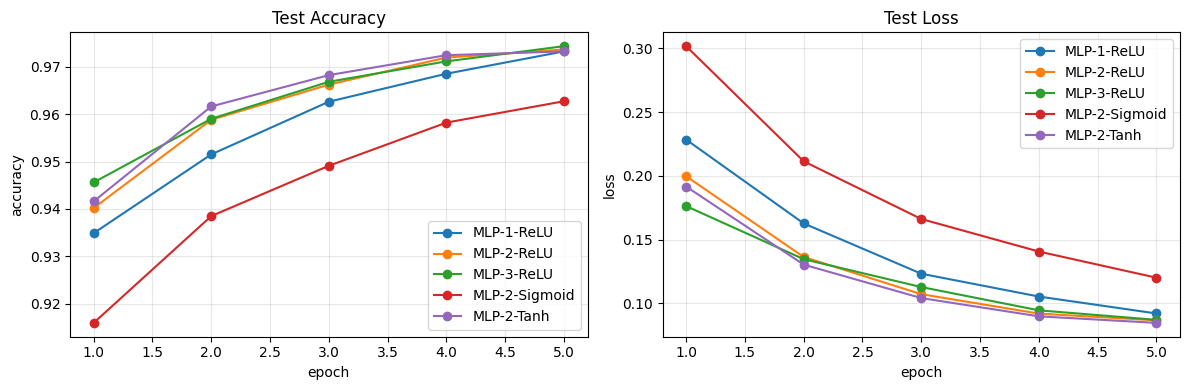

In [5]:
# 답안
table = pd.DataFrame([
    {"모델": k, **{c: v[c] for c in ["은닉층 수", "활성화", "파라미터 수", "시험 정확도"]}}
    for k, v in results.items()
])
display(table)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, r in results.items():
    epochs = range(1, len(r["hist"]) + 1)
    axes[0].plot(epochs, [h[1] for h in r["hist"]], marker="o", label=name)
    axes[1].plot(epochs, [h[0] for h in r["hist"]], marker="o", label=name)
axes[0].set_title("Test Accuracy"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("accuracy")
axes[1].set_title("Test Loss");     axes[1].set_xlabel("epoch"); axes[1].set_ylabel("loss")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 문제 4. 해석 (10점)
아래 세 가지를 각각 두세 줄로 적으세요.

1. 은닉층을 늘렸을 때 정확도가 어떻게 변했는가 — 계속 좋아지는가
2. Sigmoid가 ReLU보다 느리게 학습되는 이유
3. 가장 좋았던 조합과 그 이유


**답:**

1.1층에서 2층으로 늘리면 정확도가 약간 오르지만, 3층에서는 거의 같거나 오히려 약간 떨어질 수 있습니다. MNIST처럼 단순한 데이터는 얕은 모델로도 충분히 표현할 수 있습니다. 그래서 층을 늘린다고 계속 좋아지지 않고, 5 epoch처럼 짧게 학습하면 깊은 모델은 덜 수렴하기도 합니다.

2.Sigmoid의 기울기는 최대 0.25이고, 입력이 크거나 작으면 0에 가까워집니다(포화). 역전파에서 이런 작은 값이 층마다 곱해지면 기울기가 소실되어 가중치 갱신이 느려집니다. 또 출력이 0을 중심으로 분포하지 않아서(항상 양수) 최적화가 비효율적입니다. ReLU는 양수 구간의 기울기가 1이라 이런 문제가 적습니다.

3.ReLU를 쓰면 기울기가 잘 전달되어 빨리 수렴합니다. 2층이면 데이터를 표현하기에 충분하면서도 과하게 깊지 않아 5 epoch 안에 잘 학습됩니다.


## 문제 5. 오류 사례 확인 (보너스)
가장 좋았던 모델로 틀리게 예측한 이미지 8장을 그리고, 어떤 숫자를 어떤 숫자로 착각했는지 적으세요.


best model: MLP-3-ReLU


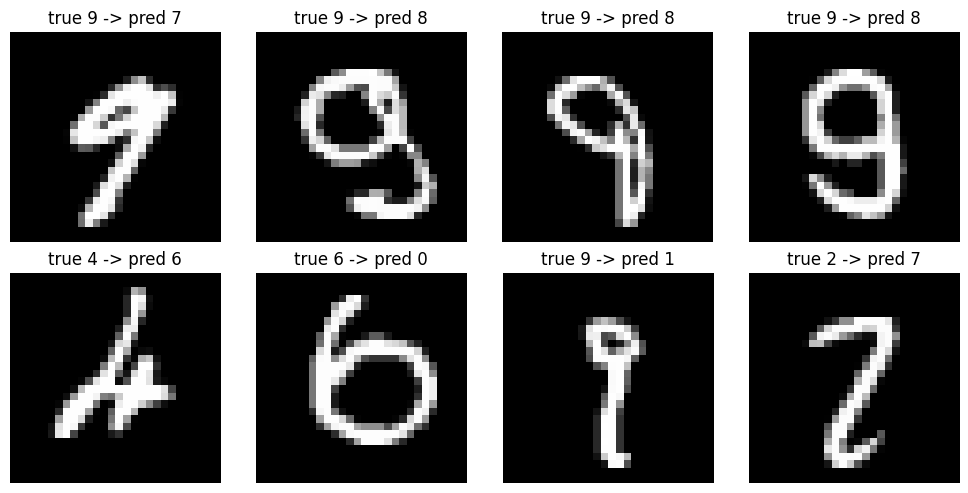

1. 실제 9 를 7 로 착각
2. 실제 9 를 8 로 착각
3. 실제 9 를 8 로 착각
4. 실제 9 를 8 로 착각
5. 실제 4 를 6 로 착각
6. 실제 6 를 0 로 착각
7. 실제 9 를 1 로 착각
8. 실제 2 를 7 로 착각


In [7]:
# 답안
best_name = max(results, key=lambda k: results[k]["시험 정확도"])
best_model = models[best_name]
print("best model:", best_name)

best_model.eval()
wrong_imgs, wrong_true, wrong_pred = [], [], []
with torch.no_grad():
    for x, y in test_loader:
        pred = best_model(x.to(device)).argmax(dim=1).cpu()
        mask = pred != y
        wrong_imgs += list(x[mask])
        wrong_true += y[mask].tolist()
        wrong_pred += pred[mask].tolist()
        if len(wrong_imgs) >= 8:
            break

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, img, t, p in zip(axes.flat, wrong_imgs[:8], wrong_true, wrong_pred):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"true {t} -> pred {p}")
    ax.axis("off")
plt.tight_layout(); plt.show()

for i, (t, p) in enumerate(zip(wrong_true[:8], wrong_pred[:8]), 1):
    print(f"{i}. 실제 {t} 를 {p} 로 착각")